# 01. Entrada de dados e ETL

Primeiro notebook do ciclo. Ele busca no Open-Meteo os dias que ainda não temos, grava esses dias como um lote novo em `data/raw/`, junta tudo, faz o diagnóstico, limpa, valida e monta os atributos. No fim ele abre o ciclo, com o `cycle_id` e o `data_version` que os notebooks seguintes vão usar.

## Problema, dados e avaliação (etapa 1)

**Problema.** Regressão: prever a temperatura máxima do dia seguinte em Jaraguá do Sul (SC) usando o que se sabe até o fim do dia de hoje.

**Fonte e licença.** Historical Weather API do Open-Meteo, com a reanálise ERA5-Seamless (ERA5 e ERA5-Land, do Copernicus/ECMWF). A API é gratuita, não pede chave e os dados são CC BY 4.0, então podem ser usados citando a fonte ("Weather data by Open-Meteo.com"). Os dias que o ERA5 ainda não publicou vêm da Forecast API do mesmo Open-Meteo, com a mesma licença.

**Unidade de observação.** Um dia em Jaraguá do Sul (ponto -26,49; -49,07), agregado no fuso de São Paulo. A série começa em 01/01/2010.

**Variável-alvo.** `alvo` = `tmax` do dia t+1, em °C.

**Atributos.** Do próprio dia: máxima, mínima e média da temperatura, umidade relativa, ponto de orvalho, pressão ao nível do mar, nebulosidade, vento médio e máximo, rajada, direção do vento, chuva e radiação solar. Construídos aqui: lags e médias móveis da máxima, variações de um dia para o outro, chuva acumulada e a época do ano.

**Limitações.** Reanálise não é estação meteorológica: é um modelo que junta observações numa grade de 9 a 25 km, então suaviza os extremos locais. O ERA5 chega com cerca de 7 dias de atraso, então os dias que ainda faltam até a véspera da previsão vêm da API de previsão do Open-Meteo, como dado provisório, só para montar a linha da previsão (seção "Dias provisórios para a previsão"). E é uma série de um ponto só.

**Métrica principal.** MAE em °C, definida no `config.yaml` antes de qualquer treino. Ela está na unidade do problema ("erra em média 1,8 °C"), não deixa poucos dias atípicos dominarem como o RMSE e é fácil de comparar com a referência ingênua da persistência (amanhã = hoje). RMSE e R² são registrados como apoio.

**Particionamento.** Série temporal, então nada de embaralhar. Com as linhas em ordem de data: treino | validação (365 dias) | teste (30 dias). A validação tem um ano inteiro para a comparação passar por todas as estações. Tudo o que o ciclo decide (votação, vencedor entre A e B, promoção) usa só treino e validação. O teste fica reservado para a avaliação final do modelo vigente, no notebook 05.

**Chegada de novos dados.** Cada execução agendada pergunta à API pelos dias depois do último que já temos e grava o que vier num arquivo `lote_<inicio>_<fim>.csv`. Como as janelas são contadas a partir do fim da série, um dia novo entra no teste e empurra um dia da validação para o treino.

In [1]:
import sys
sys.path.insert(0, "..")

import matplotlib.pyplot as plt
import pandas as pd
from src import ciclo, ingestao, preprocessamento

cfg = ciclo.carregar_config()
pd.set_option("display.precision", 2)

## Entrada e versionamento dos dados

`ingestao.atualizar` consulta a API a partir do dia seguinte ao último que já está em `data/raw/`. Só entram dias completos (o ERA5 devolve os dias recentes vazios), então o mesmo dia nunca é gravado duas vezes.

In [2]:
lote = ingestao.atualizar(cfg)
lote

{'n_novos': 1,
 'arquivo': 'lote_20261103_20261103.csv',
 'inicio': '2026-11-03',
 'fim': '2026-11-03',
 'consultado': ['2026-11-03', '2026-11-10']}

In [3]:
bruto = ingestao.carregar_bruto()
print(f"{len(bruto)} dias, de {bruto.data.min():%d/%m/%Y} a {bruto.data.max():%d/%m/%Y}, em {bruto.lote.nunique()} lote(s)")
bruto.groupby("lote").data.agg(["min", "max", "count"])

6151 dias, de 01/01/2010 a 03/11/2026, em 5 lote(s)


,min,max,count
lote,,,
lote_20100101_20261024,2010-01-01,2026-10-24,6141
lote_20261025_20261031,2026-10-25,2026-10-31,7
lote_20261101_20261101,2026-11-01,2026-11-01,1
lote_20261102_20261102,2026-11-02,2026-11-02,1
lote_20261103_20261103,2026-11-03,2026-11-03,1


## Diagnóstico antes da limpeza

Conferimos ausentes, datas duplicadas, dias faltando no calendário, valores fisicamente impossíveis (fora de uma faixa plausível para a região), mínima maior que a máxima e outliers pelo z robusto (distância até a mediana dividida pelo desvio absoluto mediano).

In [4]:
diag_antes, geral_antes = preprocessamento.diagnostico(bruto)
print(geral_antes)
diag_antes

{'linhas': 6151, 'datas_duplicadas': 0, 'dias_faltando': 0, 'tmin_maior_que_tmax': 0}


,ausentes,fora_da_faixa,outliers_z5,min,max
tmax,0,0,0,9.70,37.30
tmin,0,0,0,2.70,26.20
tmed,0,0,0,8.20,30.80
umidade,0,0,22,48.00,98.00
orvalho,0,0,0,0.30,26.40
pressao,0,0,0,996.20,1032.50
nuvens,0,0,0,0.00,100.00
vento_max,0,0,9,3.40,37.40
vento_med,0,0,40,1.80,25.30
rajada,0,0,15,10.40,86.40


## Tratamentos

- **Data repetida:** fica a versão do lote mais novo.
- **Dia faltando:** vira uma linha vazia, para os lags e as médias móveis sempre olharem para o dia anterior de verdade.
- **Valor fora da faixa física, ou mínima maior que a máxima:** vira ausente. A imputação (mediana) acontece depois, dentro do Pipeline, ajustada só com o treino, para não vazar informação da validação e do teste.
- **Outlier:** só é sinalizado. Em clima, um dia muito quente ou uma frente fria forte são dados reais, e são justamente os dias difíceis de prever.

In [5]:
limpo = preprocessamento.limpar(bruto)
diag_depois, geral_depois = preprocessamento.diagnostico(limpo)
colunas = ["ausentes", "fora_da_faixa", "outliers_z5"]
comparacao = pd.concat({"antes": diag_antes[colunas], "depois": diag_depois[colunas]}, axis=1)
print("antes: ", geral_antes)
print("depois:", geral_depois)
comparacao

antes:  {'linhas': 6151, 'datas_duplicadas': 0, 'dias_faltando': 0, 'tmin_maior_que_tmax': 0}
depois: {'linhas': 6151, 'datas_duplicadas': 0, 'dias_faltando': 0, 'tmin_maior_que_tmax': 0}


antes                             depois                \
          ausentes fora_da_faixa outliers_z5 ausentes fora_da_faixa   
tmax             0             0           0        0             0   
tmin             0             0           0        0             0   
tmed             0             0           0        0             0   
umidade          0             0          22        0             0   
orvalho          0             0           0        0             0   
pressao          0             0           0        0             0   
nuvens           0             0           0        0             0   
vento_max        0             0           9        0             0   
vento_med        0             0          40        0             0   
rajada           0             0          15        0             0   
vento_dir        0             0           0        0             0   
chuva            0             0        1027        0             0   
radiacao         0             0           0        0             0   

                       
          outliers_z5  
tmax                0  
tmin                0  
tmed                0  
umidade            22  
orvalho             0  
pressao             0  
nuvens              0  
vento_max           9  
vento_med          40  
rajada             15  
vento_dir           0  
chuva            1027  
radiacao            0

A validação para o pipeline se faltar coluna, se houver data repetida ou buraco no calendário depois da limpeza, ou se mais de 1% do alvo estiver ausente. Se ela falhar, o notebook dá erro, o workflow para e nenhum modelo é promovido.

In [6]:
preprocessamento.validar(limpo, cfg)
print("validação ok")

validação ok


## Engenharia de atributos

Tudo olha só para trás (até o dia t) e o alvo é a máxima de t+1, então nenhum atributo carrega informação do futuro.

- `tmax_lag1`, `tmax_lag2`, `tmax_lag3`, `tmax_media3`, `tmax_media7`: a temperatura tem muita inércia, os últimos dias dizem muito sobre amanhã.
- `tmax_delta`: se esquentou ou esfriou de ontem para hoje.
- `amplitude` (máxima menos mínima): dia de céu aberto tem amplitude grande, dia nublado e chuvoso tem amplitude pequena.
- `pressao_delta`: pressão caindo costuma anunciar a chegada de frente fria.
- `umidade_delta` e `chuva_3d`: tempo virando para chuvoso.
- `vento_dir_sin` e `vento_dir_cos`: direção do vento é circular (350° fica perto de 10°). Vento de norte e noroeste costuma esquentar, vento de sul costuma esfriar.
- `dia_ano_sin` e `dia_ano_cos`: a época do ano, sem o salto entre 31/12 e 01/01.

In [7]:
dataset = preprocessamento.construir_atributos(limpo)
janelas = preprocessamento.dividir(dataset, cfg)
ciclo.PROCESSED.mkdir(parents=True, exist_ok=True)
dataset.to_csv(ciclo.PROCESSED / "dataset.csv")
print(f"{dataset.shape[1] - 1} atributos candidatos")
pd.DataFrame({nome: {"início": j.index.min().date(), "fim": j.index.max().date(), "dias": len(j)}
              for nome, j in janelas.items()}).T

26 atributos candidatos


,início,fim,dias
treino,2010-01-07,2025-10-03,5749
validacao,2025-10-04,2026-10-03,365
teste,2026-10-04,2026-11-02,30
proximo,2026-11-03,2026-11-03,1


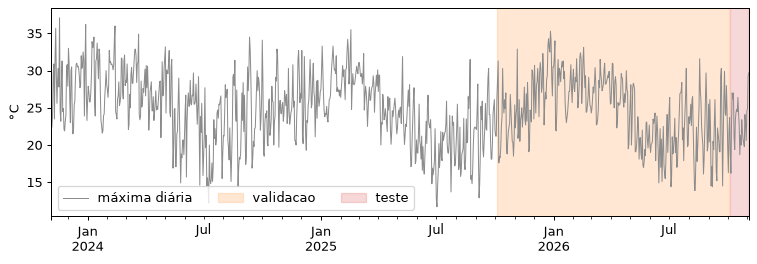

In [8]:
fig, ax = plt.subplots(figsize=(10, 3), dpi=90)
dataset.tmax.iloc[-3 * 365:].plot(ax=ax, color="0.55", lw=0.8, label="máxima diária")
for nome, cor in [("validacao", "tab:orange"), ("teste", "tab:red")]:
    ax.axvspan(janelas[nome].index.min(), janelas[nome].index.max(), color=cor, alpha=0.18, label=nome)
ax.set_ylabel("°C")
ax.set_xlabel("")
ax.legend(loc="lower left", ncols=3)
plt.show()

## Dias provisórios para a previsão

O ERA5 chega com uns 7 dias de atraso. Para a previsão sair para o dia atual, os dias que ele ainda não publicou vêm da API de previsão do Open-Meteo, que é dado provisório de modelos de previsão do tempo. Eles entram só na linha da previsão: treino, validação e teste continuam só com ERA5, e a previsão é conferida com o ERA5 quando ele chegar. Os dias usados ficam em `evidencias/ciclos/<cycle_id>/provisorio.csv`.

In [9]:
provisorio = ingestao.buscar_recentes(cfg, bruto.data.max())
janelas["proximo"] = preprocessamento.linha_da_previsao(bruto, provisorio)
janelas["proximo"].to_csv(ciclo.PROCESSED / "proximo.csv")
base = janelas["proximo"].index[0]
if len(provisorio):
    print(f"{len(provisorio)} dias provisórios, de {provisorio.data.min():%d/%m} a {provisorio.data.max():%d/%m/%Y}")
print(f"a previsão usa os dados até {base:%d/%m/%Y} e sai para {base + pd.Timedelta(days=1):%d/%m/%Y}")
provisorio

6 dias provisórios, de 04/11 a 09/11/2026
a previsão usa os dados até 09/11/2026 e sai para 10/11/2026


,data,tmax,tmin,tmed,umidade,orvalho,pressao,nuvens,vento_max,vento_med,rajada,vento_dir,chuva,radiacao
0,2026-11-04,22.5,19.4,20.6,96,19.9,1010.3,99,6.4,2.8,24.1,185,21.9,7.33
1,2026-11-05,28.1,19.6,22.9,86,20.3,1009.1,81,14.5,6.0,33.1,87,4.2,16.62
2,2026-11-06,27.0,18.8,22.0,80,18.3,1014.0,85,13.7,5.5,32.0,76,1.6,15.33
3,2026-11-07,24.2,18.2,20.6,96,19.9,1009.7,96,11.6,4.4,31.7,135,13.2,10.11
4,2026-11-08,21.9,16.7,18.6,79,14.7,1020.3,84,15.0,7.3,37.4,87,3.6,16.65
5,2026-11-09,22.6,14.3,18.2,72,12.6,1026.2,53,11.7,5.2,32.0,89,2.0,23.18


## Abertura do ciclo

O `data_version` é o último dia da série mais o início do sha256 dos arquivos de `data/raw/`. Se nada mudou nos dados, a versão é a mesma. Qualquer dia novo gera outra.

In [10]:
estado = ciclo.novo_ciclo(
    data_version=ingestao.versao_dados(bruto),
    lote=lote,
    dados={"linhas": len(bruto), "inicio": str(bruto.data.min().date()), "fim": str(bruto.data.max().date()),
           "lotes": sorted(bruto.lote.unique())},
    janelas={nome: [str(j.index.min().date()), str(j.index.max().date()), len(j)] for nome, j in janelas.items()},
    diagnostico={"antes": geral_antes, "depois": geral_depois},
    provisorio=({"inicio": str(provisorio.data.min().date()), "fim": str(provisorio.data.max().date()),
                 "dias": len(provisorio), "fonte": cfg["dados"]["provisorio"]["fonte"]} if len(provisorio) else None),
)
comparacao.to_csv(ciclo.pasta(estado) / "diagnostico.csv")
if len(provisorio):
    provisorio.to_csv(ciclo.pasta(estado) / "provisorio.csv", index=False)
print(estado["cycle_id"], estado["data_version"])

20261110-184307 dv-20261103-541a98c0
